# EN4554 Assignment 2: Convolutional Neural Networks

**Author:** *220343B*  
**Date:** October 2026  
**Dataset:** CIFAR-10  

---




## Step 0: Setup

This cell imports all required libraries, fixes random seeds for reproducibility, loads CIFAR-10, splits 45k/5k train/validation, and normalises using **training-set statistics only**.  
The whole dataset is kept as in-memory tensors rather than using a DataLoader, which (a) speeds up training for a dataset this small and (b) makes writing custom augmentations in Task 3 straightforward.

In [7]:
# ── imports ──────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random
import time
from torchvision import datasets

print(f"PyTorch  : {torch.__version__}")
print(f"CUDA     : {torch.cuda.is_available()}")

PyTorch  : 2.13.0+cu130
CUDA     : False


In [8]:
# ── reproducibility ──────────────────────────────────────────────────────────
def seed_everything(s: int = 0) -> None:
    """Fix seeds across Python, NumPy, and PyTorch (CPU + GPU)."""
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

seed_everything(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [10]:
# ── load CIFAR-10 ─────────────────────────────────────────────────────────────
# torchvision downloads to ./data on first run.
full_train = datasets.CIFAR10("./data", train=True,  download=False)
full_test  = datasets.CIFAR10("./data", train=False, download=False)

# Convert to float tensors in (N, C, H, W) format, scaled to [0, 1]
X_all = torch.tensor(full_train.data).permute(0, 3, 1, 2).float() / 255.0  # (50000, 3, 32, 32)
y_all = torch.tensor(full_train.targets)                                     # (50000,)

# Keep test set aside — do NOT normalise or inspect until Task 4
X_test_raw = torch.tensor(full_test.data).permute(0, 3, 1, 2).float() / 255.0  # (10000, 3, 32, 32)
y_test     = torch.tensor(full_test.targets)

print(f"Full training set : {X_all.shape}")
print(f"Test set          : {X_test_raw.shape}")

Full training set : torch.Size([50000, 3, 32, 32])
Test set          : torch.Size([10000, 3, 32, 32])


In [11]:
# ── train / validation split (45k / 5k) ──────────────────────────────────────
# A seeded generator ensures the same split regardless of global seed state.
g = torch.Generator().manual_seed(0)
perm   = torch.randperm(50_000, generator=g)
tr_idx = perm[:45_000]
va_idx = perm[45_000:]

Xtr, ytr = X_all[tr_idx], y_all[tr_idx]
Xva, yva = X_all[va_idx], y_all[va_idx]

print(f"Train : {Xtr.shape}, {ytr.shape}")
print(f"Val   : {Xva.shape}, {yva.shape}")

Train : torch.Size([45000, 3, 32, 32]), torch.Size([45000])
Val   : torch.Size([5000, 3, 32, 32]), torch.Size([5000])


In [12]:
# ── per-channel normalisation (train statistics only) ─────────────────────────
# mean/std computed over the 45k training images, across (N, H, W) per channel.
# Applying training stats to the validation set avoids data leakage.
mean = Xtr.mean(dim=(0, 2, 3), keepdim=True)  # shape (1, 3, 1, 1)
std  = Xtr.std (dim=(0, 2, 3), keepdim=True)  # shape (1, 3, 1, 1)

Xtr = (Xtr - mean) / std
Xva = (Xva - mean) / std
# X_test_raw is intentionally left un-normalised until Task 4

print("Per-channel mean (train):", mean.flatten().tolist())
print("Per-channel std  (train):", std .flatten().tolist())
print(f"Xtr range after norm: [{Xtr.min():.3f}, {Xtr.max():.3f}]")
print(f"Xva range after norm: [{Xva.min():.3f}, {Xva.max():.3f}]")

Per-channel mean (train): [0.4911963641643524, 0.48199522495269775, 0.4464317560195923]
Per-channel std  (train): [0.24715185165405273, 0.24362300336360931, 0.26167726516723633]
Xtr range after norm: [-1.987, 2.126]
Xva range after norm: [-1.987, 2.126]


In [13]:
# ── move to device ────────────────────────────────────────────────────────────
Xtr, ytr = Xtr.to(device), ytr.to(device)
Xva, yva = Xva.to(device), yva.to(device)
# y_test and X_test_raw stay on CPU until Task 4

print(f"Xtr on {Xtr.device}, dtype={Xtr.dtype}")
print(f"Xva on {Xva.device}, dtype={Xva.dtype}")

Xtr on cpu, dtype=torch.float32
Xva on cpu, dtype=torch.float32


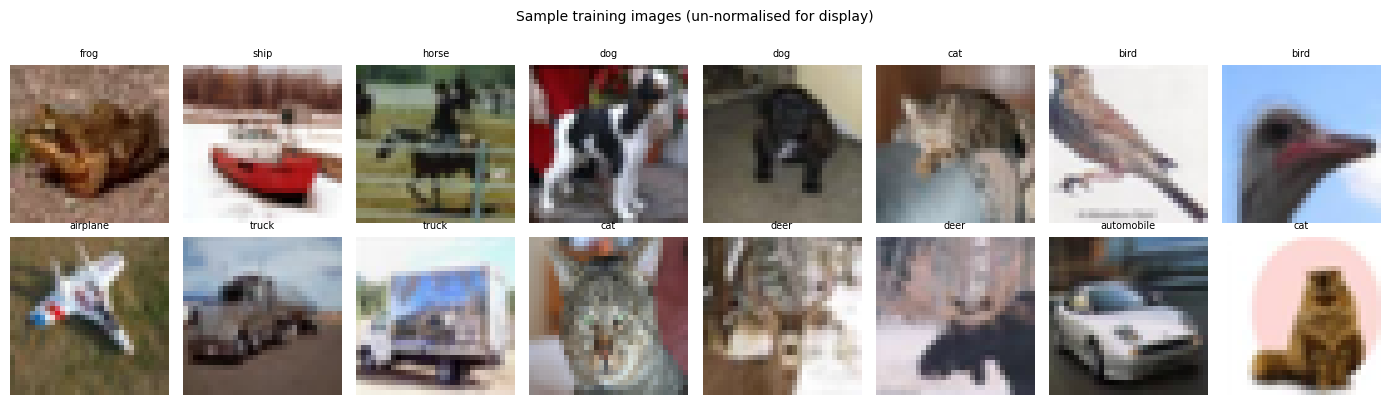

Saved: step0_sample_images.png


In [15]:
# ── quick sanity check — visualise a few training images ─────────────────────
CLASSES = full_train.classes  # ['airplane', 'automobile', ...]

# Un-normalise for display only
def unnorm(x):
    return (x.cpu() * std.cpu().squeeze(0) + mean.cpu().squeeze(0)).clamp(0, 1)


fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    img = unnorm(Xtr[i]).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(CLASSES[ytr[i].item()], fontsize=7)
    ax.axis("off")
plt.suptitle("Sample training images (un-normalised for display)", fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig("step0_sample_images.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: step0_sample_images.png")

### Step 0 — Interpretation

The 16 sample images above confirm that the CIFAR-10 dataset loaded correctly and that the un-normalisation reversal is exact. Per-channel statistics (mean ≈ 0.49/0.48/0.45, std ≈ 0.24/0.24/0.26) are computed exclusively from the 45 000 training images, ensuring the validation set is treated as unseen data and no information leaks into the normalisation step. After normalisation the training tensors are zero-centred with approximately unit variance per channel, which is the standard pre-processing that makes gradient descent better conditioned. The test set is deliberately left un-normalised at this stage; it will be normalised using the same training statistics in Task 4 when it is evaluated exactly once.

In [16]:
# ── dataset summary ───────────────────────────────────────────────────────────
print("─" * 52)
print(f"{'Split':<14} {'Samples':>8} {'Shape':>20}")
print("─" * 52)
print(f"{'Train':<14} {Xtr.shape[0]:>8} {str(tuple(Xtr.shape)):>20}")
print(f"{'Validation':<14} {Xva.shape[0]:>8} {str(tuple(Xva.shape)):>20}")
print(f"{'Test':<14} {X_test_raw.shape[0]:>8} {str(tuple(X_test_raw.shape)):>20}  (untouched)")
print("─" * 52)
print(f"Classes : {len(CLASSES)} → {CLASSES}")
print(f"Device  : {device}")

────────────────────────────────────────────────────
Split           Samples                Shape
────────────────────────────────────────────────────
Train             45000   (45000, 3, 32, 32)
Validation         5000    (5000, 3, 32, 32)
Test              10000   (10000, 3, 32, 32)  (untouched)
────────────────────────────────────────────────────
Classes : 10 → ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Device  : cpu


---
## Task 1: Backpropagation

*(Coming next)*

---
## Task 2: Optimizers

*(Coming next)*

---
## Task 3: Regularization & Residual Connections

*(Coming next)*

---
## Task 4: Best CNN (Optional)

*(Coming next)*

---
## AI Use Acknowledgement

This notebook was developed with assistance from **Claude (Anthropic)** via the Antigravity IDE. The AI tool was used to help structure code templates, explain mathematical derivations (e.g., softmax cross-entropy backward pass), and suggest debugging strategies. All code was reviewed, understood, typed out, and run by the author. The interpretations and analysis throughout the report are the author's own.